<a href="https://colab.research.google.com/github/khansa-020/Breast_Lesion_segmentation/blob/main/01_eda_DMID_BC_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DMID Breast Cancer Segmentation — Initial EDA (Google Colab)

This notebook inspects the DMID dataset before building the segmentation pipeline.

**Dataset folders expected:**
- `DMID/TIFF Images/TIFF Images` — 510 TIFF images
- `DMID/Pixel-level annotation/Pixel-level annotation` — 269 annotation masks
- `DMID/ROI Masks/ROI Masks` — 269 ROI masks

Do not assume that every image has a mask. This notebook checks filenames, dimensions, pixel values, and possible image-mask matching. It does not modify the original dataset.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Upload the dataset zip to Drive first, then:
!unzip -q "/content/drive/MyDrive/breast-cancer-segmentation/data/DMID.zip" -d /content/DMID

Mounted at /content/drive


## 2. Set dataset paths

Update `DATA_ROOT` to the folder that contains the `DMID` directory in your Google Drive.

For example, if your folder is `MyDrive/breast-cancer-segmentation/data/DMID`, keep the path below.

In [ ]:
from pathlib import Path

DATA_ROOT = Path('/content/DMID')

IMAGE_DIR = DATA_ROOT / 'TIFF Images' / 'TIFF Images'
PIXEL_MASK_DIR = DATA_ROOT / 'Pixel-level annotation' / 'Pixel-level annotation'
ROI_MASK_DIR = DATA_ROOT / 'ROI Masks' / 'ROI Masks'

for name, path in {
    'Images': IMAGE_DIR,
    'Pixel-level annotations': PIXEL_MASK_DIR,
    'ROI masks': ROI_MASK_DIR
}.items():
    print(f'{name}: {path} | exists={path.exists()}')
    if not path.exists():
        print('  WARNING: Check the folder name and DATA_ROOT.')

Images: /content/DMID/TIFF Images/TIFF Images | exists=True
Pixel-level annotations: /content/DMID/Pixel-level annotation/Pixel-level annotation | exists=True
ROI masks: /content/DMID/ROI Masks/ROI Masks | exists=True


## 3. Install/import libraries

In [ ]:
!pip -q install tifffile
!pip install imagecodecs


import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tifffile
from collections import Counter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.7/27.7 MB 56.8 MB/s  0:00:00


## 4. List files and verify the dataset counts

In [ ]:
VALID_EXTENSIONS = {'.tif', '.tiff'}

def get_image_files(folder):
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob('*')
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )

image_files = get_image_files(IMAGE_DIR)
pixel_mask_files = get_image_files(PIXEL_MASK_DIR)
roi_mask_files = get_image_files(ROI_MASK_DIR)

counts = pd.DataFrame({
    'Dataset component': ['TIFF images', 'Pixel-level annotations', 'ROI masks'],
    'Files found': [len(image_files), len(pixel_mask_files), len(roi_mask_files)],
    'Expected count': [510, 269, 269]
})
display(counts)

print('\nFirst 10 image filenames:')
for p in image_files[:10]:
    print(p.name)

print('\nFirst 10 pixel-level annotation filenames:')
for p in pixel_mask_files[:10]:
    print(p.name)

print('\nFirst 10 ROI mask filenames:')
for p in roi_mask_files[:10]:
    print(p.name)

,Dataset component,Files found,Expected count
0,TIFF images,511,510
1,Pixel-level annotations,269,269
2,ROI masks,269,269



First 10 image filenames:
IMG001.tif
IMG002.tif
IMG003.tif
IMG004.tif
IMG005.tif
IMG006.tif
IMG007.tif
IMG008.tif
IMG009.tif
IMG010.tif

First 10 pixel-level annotation filenames:
IMG001.tif
IMG008.tif
IMG010.tif
IMG011.tif
IMG012.tif
IMG014.tif
IMG015.tif
IMG021.tif
IMG024.tif
IMG025.tif

First 10 ROI mask filenames:
IMG001.tif
IMG008.tif
IMG010.tif
IMG011.tif
IMG012.tif
IMG014.tif
IMG015.tif
IMG021.tif
IMG024.tif
IMG025.tif


In [ ]:
# new
# 5. Detect and remove duplicate images

import hashlib
import tifffile
import numpy as np
import pandas as pd

def get_pixel_hash(path):
    arr = tifffile.imread(str(path))
    arr = np.ascontiguousarray(arr)

    # Include shape and data type so different image formats
    # are not accidentally treated as identical.
    info = str(arr.shape) + str(arr.dtype)
    return hashlib.sha256(info.encode() + arr.tobytes()).hexdigest()


hash_groups = {}
unreadable_images = []

for path in image_files:
    try:
        file_hash = get_pixel_hash(path)
        hash_groups.setdefault(file_hash, []).append(path)
    except Exception as e:
        unreadable_images.append({
            'filename': path.name,
            'error': str(e)
        })

duplicate_rows = []
unique_image_files = []

for file_hash, files in hash_groups.items():

    # Keep the first file and mark the remaining files as duplicates.
    files = sorted(files, key=lambda p: p.name)
    unique_image_files.append(files[0])

    if len(files) > 1:
        for duplicate in files[1:]:
            duplicate_rows.append({
                'kept_image': files[0].name,
                'duplicate_image': duplicate.name,
                'pixel_hash': file_hash
            })

# Replace the working image list with unique images.
image_files = sorted(unique_image_files)

duplicates_df = pd.DataFrame(duplicate_rows)
unreadable_df = pd.DataFrame(unreadable_images)

print("Original image count:", len(hash_groups) + len(duplicate_rows))
print("Duplicate images found:", len(duplicate_rows))
print("Unique images remaining:", len(image_files))
print("Unreadable images:", len(unreadable_images))

display(duplicates_df)
display(unreadable_df)

Original image count: 511
Duplicate images found: 1
Unique images remaining: 510
Unreadable images: 0


,kept_image,duplicate_image,pixel_hash
0,IMG279 - Copy.tif,IMG279.tif,df6062d146d3af803d4286a78c28ae6635cca8ed38babd...


""


## 5. Check filename patterns and possible matching

This section compares filename stems. It tries a conservative exact-stem match first, then a normalized match that removes common words such as `mask`, `annotation`, and `roi`.

**Important:** A match suggested by filename similarity must still be visually checked. Do not use a guessed pairing for model training.

In [ ]:
def normalize_stem(path):
    stem = path.stem.lower()
    stem = re.sub(r'[^a-z0-9]+', '', stem)
    for token in ['pixellevelannotation', 'annotation', 'mask', 'roi', 'groundtruth', 'gt']:
        stem = stem.replace(token, '')
    return stem

def make_index(files):
    index = {}
    for p in files:
        key = normalize_stem(p)
        index.setdefault(key, []).append(p)
    return index

pixel_index = make_index(pixel_mask_files)
roi_index = make_index(roi_mask_files)

rows = []
for img in image_files:
    exact_pixel = [p for p in pixel_mask_files if p.stem.lower() == img.stem.lower()]
    exact_roi = [p for p in roi_mask_files if p.stem.lower() == img.stem.lower()]
    key = normalize_stem(img)
    norm_pixel = pixel_index.get(key, [])
    norm_roi = roi_index.get(key, [])

    rows.append({
        'image': img.name,
        'exact_pixel_mask': exact_pixel[0].name if len(exact_pixel) == 1 else '',
        'exact_roi_mask': exact_roi[0].name if len(exact_roi) == 1 else '',
        'normalized_pixel_candidates': '; '.join(p.name for p in norm_pixel),
        'normalized_roi_candidates': '; '.join(p.name for p in norm_roi),
        'pixel_candidate_count': len(norm_pixel),
        'roi_candidate_count': len(norm_roi)
    })

matching_df = pd.DataFrame(rows)
display(matching_df.head(30))

print('Images with exactly one normalized pixel-mask candidate:',
      (matching_df['pixel_candidate_count'] == 1).sum())
print('Images with exactly one normalized ROI-mask candidate:',
      (matching_df['roi_candidate_count'] == 1).sum())
print('Images with ambiguous pixel-mask candidates:',
      (matching_df['pixel_candidate_count'] > 1).sum())
print('Images with ambiguous ROI-mask candidates:',
      (matching_df['roi_candidate_count'] > 1).sum())

,image,exact_pixel_mask,exact_roi_mask,normalized_pixel_candidates,normalized_roi_candidates,pixel_candidate_count,roi_candidate_count
0,IMG001.tif,IMG001.tif,IMG001.tif,IMG001.tif,IMG001.tif,1,1
1,IMG002.tif,,,,,0,0
2,IMG003.tif,,,,,0,0
3,IMG004.tif,,,,,0,0
4,IMG005.tif,,,,,0,0
5,IMG006.tif,,,,,0,0
6,IMG007.tif,,,,,0,0
7,IMG008.tif,IMG008.tif,IMG008.tif,IMG008.tif,IMG008.tif,1,1
8,IMG009.tif,,,,,0,0
9,IMG010.tif,IMG010.tif,IMG010.tif,IMG010.tif,IMG010.tif,1,1


Images with exactly one normalized pixel-mask candidate: 268
Images with exactly one normalized ROI-mask candidate: 268
Images with ambiguous pixel-mask candidates: 0
Images with ambiguous ROI-mask candidates: 0


In [ ]:
# new
# 6. Check whether one image has multiple masks

pixel_index = make_index(pixel_mask_files)
roi_index = make_index(roi_mask_files)

mask_rows = []

for img in image_files:
    key = normalize_stem(img)

    pixel_candidates = pixel_index.get(key, [])
    roi_candidates = roi_index.get(key, [])

    mask_rows.append({
        'image': img.name,

        'pixel_mask_count': len(pixel_candidates),
        'pixel_mask_files': '; '.join(p.name for p in pixel_candidates),

        'roi_mask_count': len(roi_candidates),
        'roi_mask_files': '; '.join(p.name for p in roi_candidates),

        'multiple_pixel_masks': len(pixel_candidates) > 1,
        'multiple_roi_masks': len(roi_candidates) > 1
    })

mask_count_df = pd.DataFrame(mask_rows)

print("Images checked:", len(mask_count_df))

print(
    "Images with multiple pixel annotations:",
    mask_count_df['multiple_pixel_masks'].sum()
)

print(
    "Images with multiple ROI masks:",
    mask_count_df['multiple_roi_masks'].sum()
)

print("\nImages having multiple masks:")
display(
    mask_count_df[
        (mask_count_df['multiple_pixel_masks']) |
        (mask_count_df['multiple_roi_masks'])
    ]
)

print("\nImages with no pixel annotation:")
display(mask_count_df[mask_count_df['pixel_mask_count'] == 0])

print("\nImages with no ROI mask:")
display(mask_count_df[mask_count_df['roi_mask_count'] == 0])

Images checked: 510
Images with multiple pixel annotations: 0
Images with multiple ROI masks: 0

Images having multiple masks:


,image,pixel_mask_count,pixel_mask_files,roi_mask_count,roi_mask_files,multiple_pixel_masks,multiple_roi_masks



Images with no pixel annotation:


,image,pixel_mask_count,pixel_mask_files,roi_mask_count,roi_mask_files,multiple_pixel_masks,multiple_roi_masks
1,IMG002.tif,0,,0,,False,False
2,IMG003.tif,0,,0,,False,False
3,IMG004.tif,0,,0,,False,False
4,IMG005.tif,0,,0,,False,False
5,IMG006.tif,0,,0,,False,False
...,...,...,...,...,...,...,...
505,IMG506.tif,0,,0,,False,False
506,IMG507.tif,0,,0,,False,False
507,IMG508.tif,0,,0,,False,False
508,IMG509.tif,0,,0,,False,False



Images with no ROI mask:


,image,pixel_mask_count,pixel_mask_files,roi_mask_count,roi_mask_files,multiple_pixel_masks,multiple_roi_masks
1,IMG002.tif,0,,0,,False,False
2,IMG003.tif,0,,0,,False,False
3,IMG004.tif,0,,0,,False,False
4,IMG005.tif,0,,0,,False,False
5,IMG006.tif,0,,0,,False,False
...,...,...,...,...,...,...,...
505,IMG506.tif,0,,0,,False,False
506,IMG507.tif,0,,0,,False,False
507,IMG508.tif,0,,0,,False,False
508,IMG509.tif,0,,0,,False,False


## 6. Read TIFF files safely

The helper below reads TIFF files with `tifffile`. It converts multi-channel images to a displayable array but retains the original array for inspection.

268 images with both masks


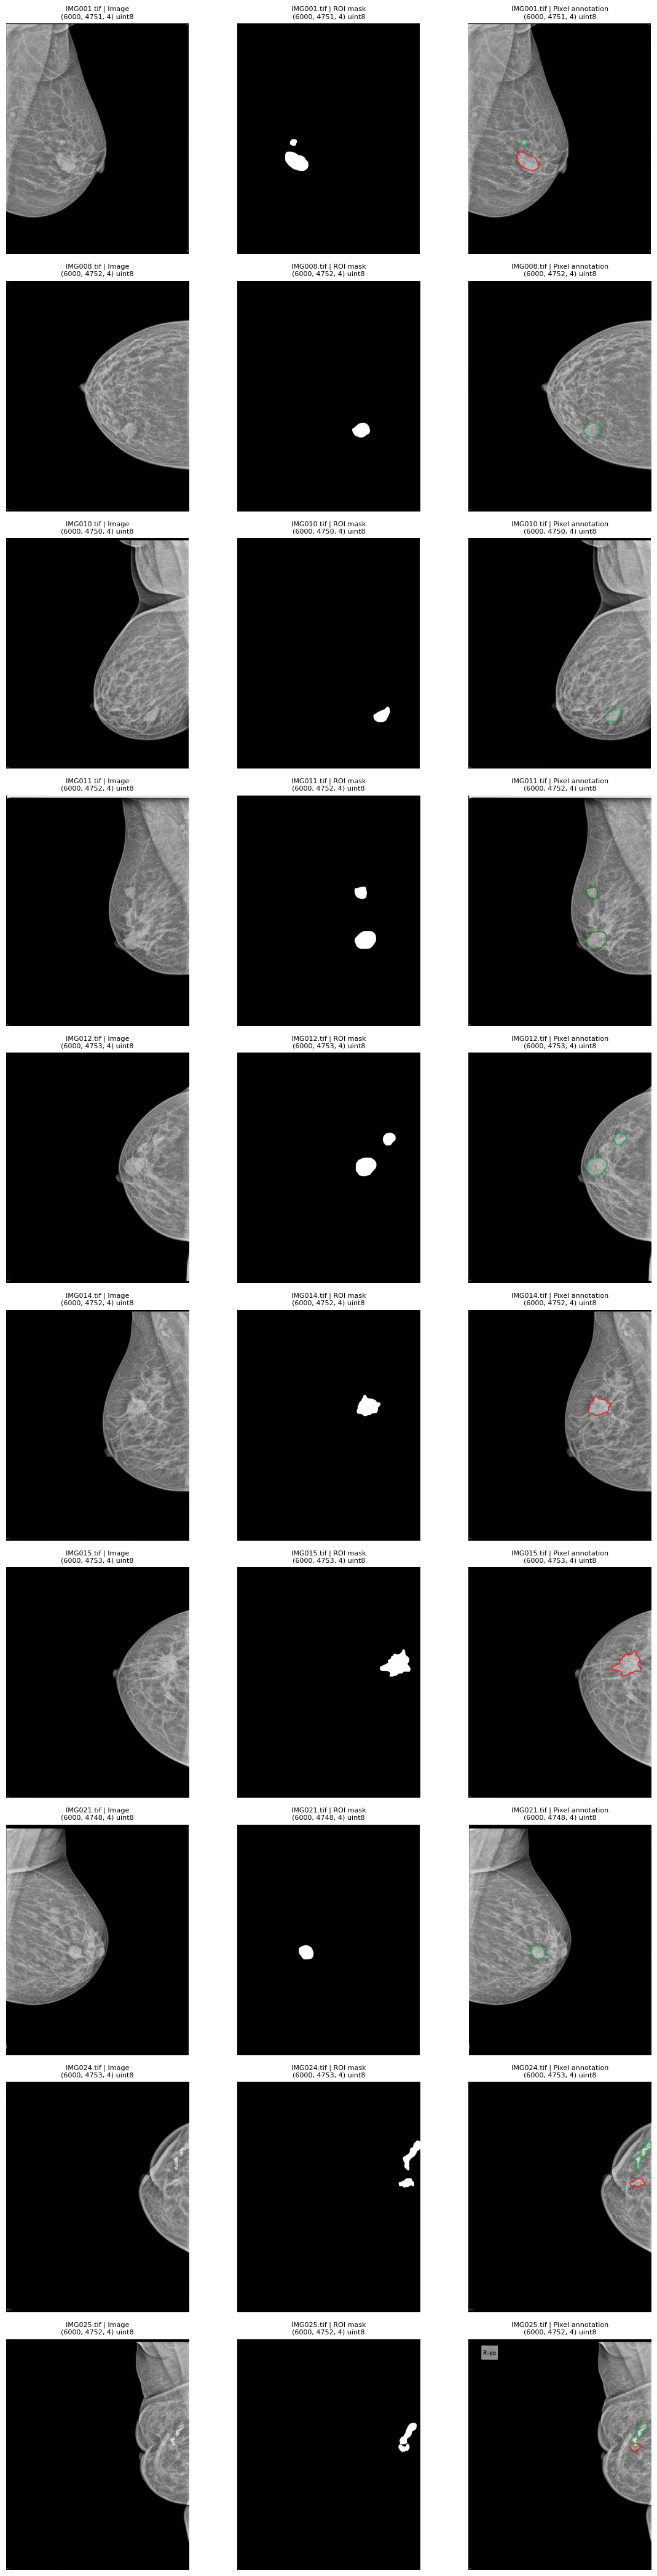

In [ ]:
import tifffile
import matplotlib.pyplot as plt

img_by = {p.name: p for p in image_files}
pix_by = {p.name: p for p in pixel_mask_files}
roi_by = {p.name: p for p in roi_mask_files}
paired = sorted(set(img_by) & set(pix_by) & set(roi_by))
print(len(paired), 'images with both masks')

N = 10
fig, axes = plt.subplots(N, 3, figsize=(12, 4.2 * N))
for r, name in enumerate(paired[:N]):
    for c, (title, path) in enumerate([('Image', img_by[name]),
                                       ('ROI mask', roi_by[name]),
                                       ('Pixel annotation', pix_by[name])]):
        arr = tifffile.imread(str(path))      # raw array, unchanged
        axes[r, c].imshow(arr, cmap='gray')   # shown as stored
        axes[r, c].set_title(f'{name} | {title}\n{arr.shape} {arr.dtype}', fontsize=8)
        axes[r, c].axis('off')
        del arr
plt.tight_layout()
plt.show()

In [ ]:

import cv2
import numpy as np

def read_image(path):
    arr = tifffile.imread(str(path))
#     return np.asarray(arr)
# def read_image(path):
#     arr = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if arr is None:
        raise ValueError(f'Could not read {path}')
    return np.asarray(arr)

def show_array_info(path):
    arr = read_image(path)
    print('File:', path.name)
    print('Shape:', arr.shape)
    print('Dtype:', arr.dtype)
    print('Min:', np.nanmin(arr), '| Max:', np.nanmax(arr))
    print('Unique values (first 20):', np.unique(arr)[:20])
    return arr

if image_files:
    sample_image = read_image(image_files[0])
    show_array_info(image_files[0])
else:
    print('No image files found. Recheck IMAGE_DIR.')

File: IMG001.tif
Shape: (6000, 4751, 4)
Dtype: uint8
Min: 0 | Max: 255
Unique values (first 20): [ 0  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


## 7. Visualize sample images

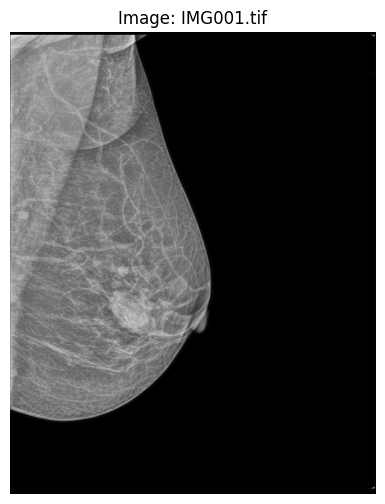

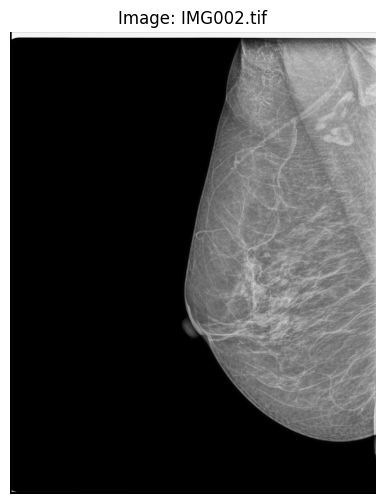

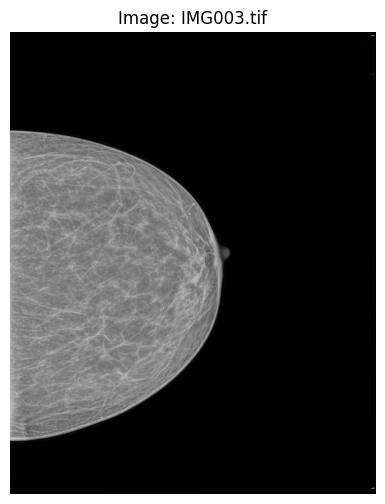

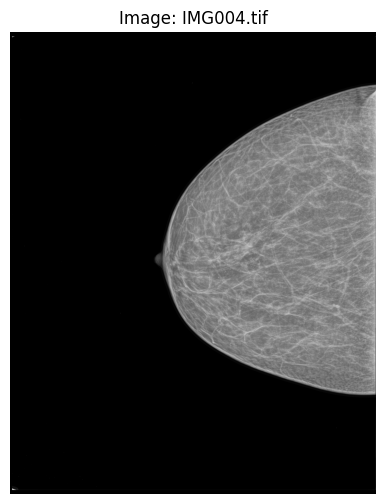

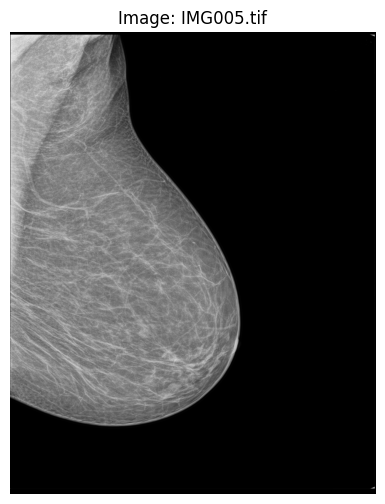

In [ ]:
def display_image(arr, title='Image', cmap=None):
    arr = np.asarray(arr)
    plt.figure(figsize=(6, 6))
    if arr.ndim == 2:
        plt.imshow(arr, cmap=cmap or 'gray')
    elif arr.ndim == 3:
        # Handle channel-first arrays if present.
        if arr.shape[0] in (3, 4) and arr.shape[-1] not in (3, 4):
            arr = np.moveaxis(arr, 0, -1)
        if arr.shape[-1] == 1:
            plt.imshow(arr[..., 0], cmap=cmap or 'gray')
        else:
            plt.imshow(arr[..., :3])
    else:
        print('Cannot directly display array with shape:', arr.shape)
        return
    plt.title(title)
    plt.axis('off')
    plt.show()

for p in image_files[:5]:
    arr = read_image(p)
    display_image(arr, f'Image: {p.name}')

annotation: (6000, 4751, 4) uint8 | image: (6000, 4751, 4) uint8
channel 0: unique=229, min=0, max=233, nonzero fraction=0.3793
channel 1: unique=229, min=0, max=233, nonzero fraction=0.3793
channel 2: unique=233, min=0, max=237, nonzero fraction=0.3793
channel 3: unique=1, min=255, max=255, nonzero fraction=1.0000


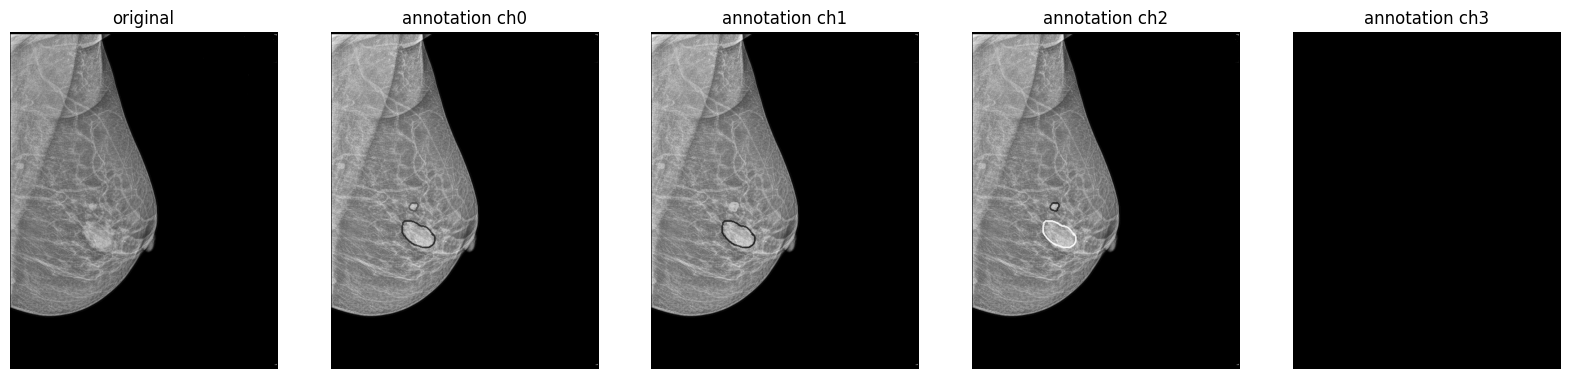

In [ ]:
import numpy as np, matplotlib.pyplot as plt

s = 'IMG001.tif'
a = read_image([p for p in pixel_mask_files if p.name == s][0])     # (H, W, 4)
img = read_image([p for p in image_files if p.name == s][0])
print('annotation:', a.shape, a.dtype | '' if False else a.dtype, '| image:', img.shape, img.dtype)

for c in range(a.shape[2]):
    ch = a[..., c]
    print(f'channel {c}: unique={len(np.unique(ch))}, min={ch.min()}, max={ch.max()}, '
          f'nonzero fraction={(ch > 0).mean():.4f}')

fig, ax = plt.subplots(1, a.shape[2] + 1, figsize=(4 * (a.shape[2] + 1), 5))
ax[0].imshow(img[::10, ::10], cmap='gray'); ax[0].set_title('original')
for c in range(a.shape[2]):
    ax[c + 1].imshow(a[::10, ::10, c], cmap='gray'); ax[c + 1].set_title(f'annotation ch{c}')
for x in ax: x.axis('off')
plt.show()

## 8. Inspect mask pixel values

For segmentation, masks are usually expected to encode background and foreground. However, the actual DMID encoding must be discovered rather than assumed.

This cell reports unique values and value counts for a sample of both mask folders.

In [ ]:
def read_image(path):
    arr = tifffile.imread(str(path))
    return np.asarray(arr)

def inspect_mask_folder(files, folder_label, max_files=10):
    records = []
    for p in files[:max_files]:
        arr = read_image(p)
        values, counts = np.unique(arr, return_counts=True)
        records.append({
            'filename': p.name,
            'shape': str(arr.shape),
            'dtype': str(arr.dtype),
            'unique_values_first_20': str(values[:20].tolist()),
            'number_of_unique_values': len(values),
            'pixel_count': int(arr.size)
        })
    print(f'--- {folder_label} ---')
    return pd.DataFrame(records)

display(inspect_mask_folder(pixel_mask_files, 'Pixel-level annotations'))
display(inspect_mask_folder(roi_mask_files, 'ROI masks'))

--- Pixel-level annotations ---


,filename,shape,dtype,unique_values_first_20,number_of_unique_values,pixel_count
0,IMG001.tif,"(6000, 4751, 4)",uint8,"[0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17...",234,114024000
1,IMG008.tif,"(6000, 4752, 4)",uint8,"[0, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,...",232,114048000
2,IMG010.tif,"(6000, 4750, 4)",uint8,"[0, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 1...",222,114000000
3,IMG011.tif,"(6000, 4752, 4)",uint8,"[0, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",227,114048000
4,IMG012.tif,"(6000, 4753, 4)",uint8,"[0, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1...",234,114072000
5,IMG014.tif,"(6000, 4752, 4)",uint8,"[0, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1...",233,114048000
6,IMG015.tif,"(6000, 4753, 4)",uint8,"[0, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",235,114072000
7,IMG021.tif,"(6000, 4748, 4)",uint8,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",253,113952000
8,IMG024.tif,"(6000, 4753, 4)",uint8,"[0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17...",242,114072000
9,IMG025.tif,"(6000, 4752, 4)",uint8,"[0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17...",234,114048000


--- ROI masks ---


,filename,shape,dtype,unique_values_first_20,number_of_unique_values,pixel_count
0,IMG001.tif,"(6000, 4751, 4)",uint8,"[0, 255]",2,114024000
1,IMG008.tif,"(6000, 4752, 4)",uint8,"[0, 255]",2,114048000
2,IMG010.tif,"(6000, 4750, 4)",uint8,"[0, 255]",2,114000000
3,IMG011.tif,"(6000, 4752, 4)",uint8,"[0, 255]",2,114048000
4,IMG012.tif,"(6000, 4753, 4)",uint8,"[0, 255]",2,114072000
5,IMG014.tif,"(6000, 4752, 4)",uint8,"[0, 255]",2,114048000
6,IMG015.tif,"(6000, 4753, 4)",uint8,"[0, 255]",2,114072000
7,IMG021.tif,"(6000, 4748, 4)",uint8,"[0, 255]",2,113952000
8,IMG024.tif,"(6000, 4753, 4)",uint8,"[0, 255]",2,114072000
9,IMG025.tif,"(6000, 4752, 4)",uint8,"[0, 255]",2,114048000


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 9. Visualize sample pixel-level annotations and ROI masks

Pixel-level annotation


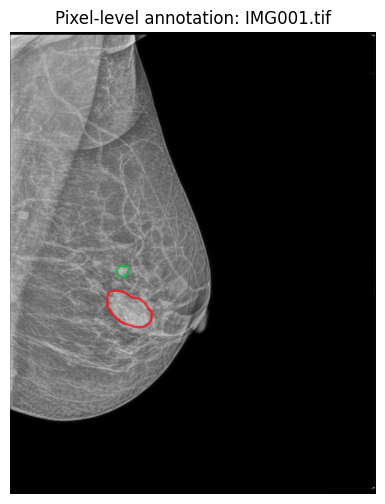

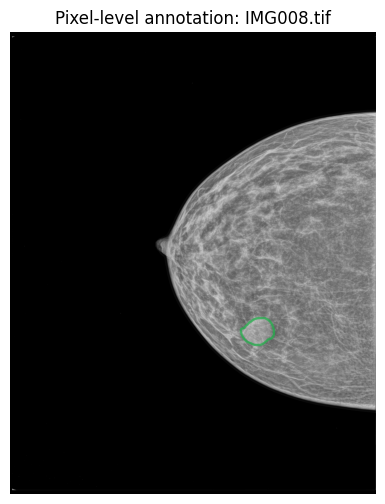

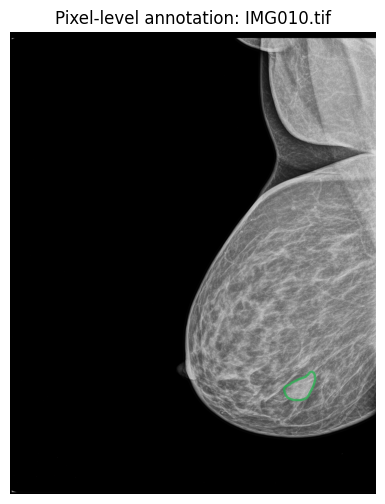

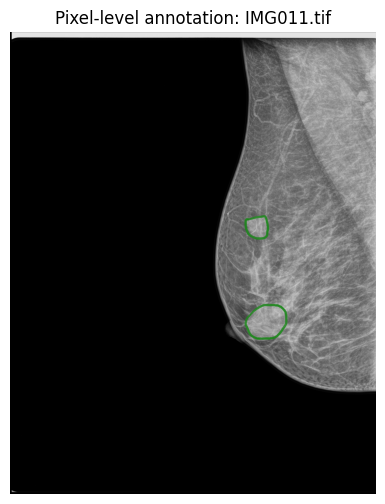

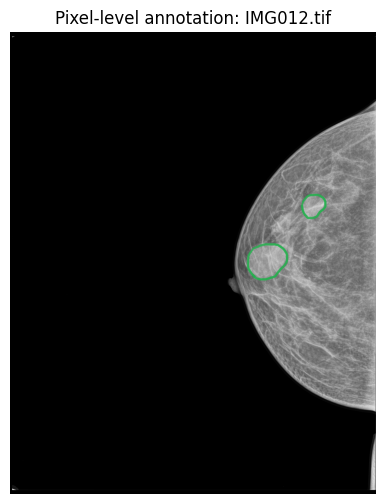

ROI mask


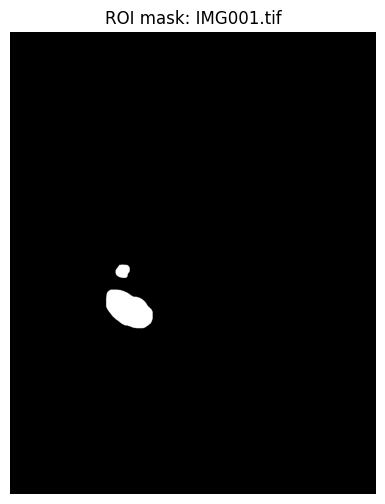

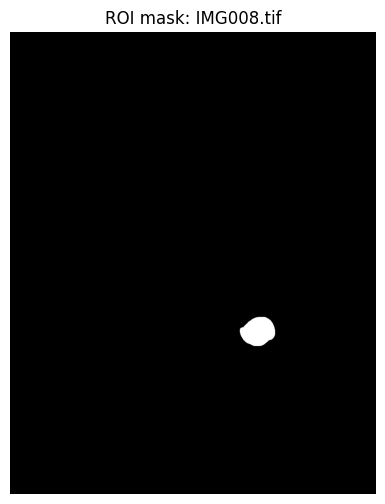

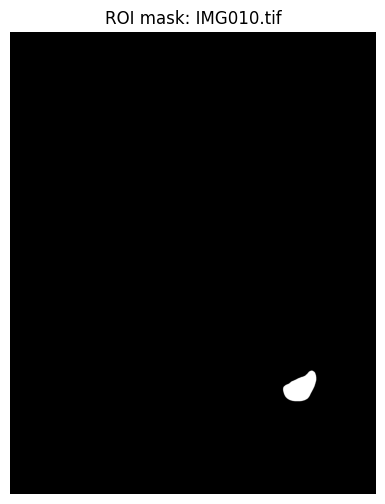

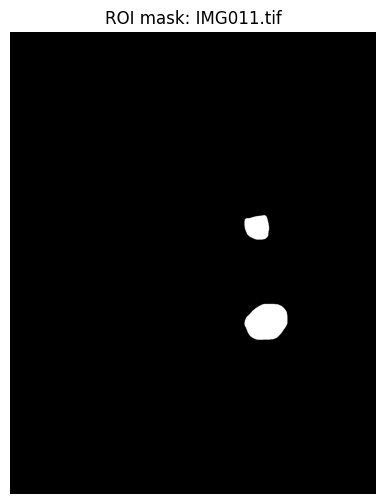

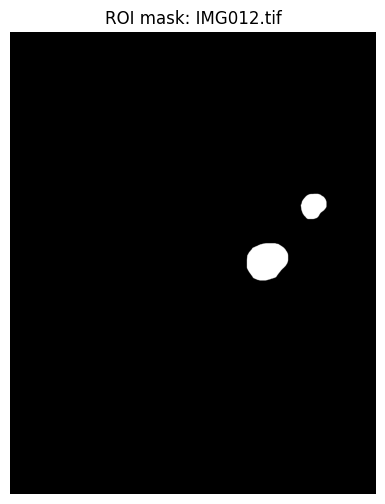

In [ ]:
def read_image(path):
    arr = tifffile.imread(str(path))
    return np.asarray(arr)

def show_mask_samples(files, label, max_items=5):
    print(label)
    for p in files[:max_items]:
        arr = read_image(p)
        display_image(arr, f'{label}: {p.name}', cmap='gray')

show_mask_samples(pixel_mask_files, 'Pixel-level annotation')
show_mask_samples(roi_mask_files, 'ROI mask')

## 10. Check image and mask dimensions

Dimension mismatches matter because a segmentation model normally needs each image and its target mask to have compatible spatial dimensions.

This cell summarizes dimensions independently. It does not resize or alter any files.

In [ ]:
def dimension_summary(files, label):
    rows = []
    for p in files:
        try:
            arr = read_image(p)
            rows.append({
                'filename': p.name,
                'height': arr.shape[0] if arr.ndim >= 2 else None,
                'width': arr.shape[1] if arr.ndim >= 2 else None,
                'shape': str(arr.shape)
            })
        except Exception as e:
            rows.append({'filename': p.name, 'height': None, 'width': None,
                         'shape': f'ERROR: {e}'})
    df = pd.DataFrame(rows)
    print(f'--- {label}: dimension frequency ---')
    if not df.empty:
        display(df.groupby(['height', 'width'], dropna=False).size()
                  .reset_index(name='file_count')
                  .sort_values('file_count', ascending=False))
    return df

image_dimensions = dimension_summary(image_files, 'Images')
pixel_dimensions = dimension_summary(pixel_mask_files, 'Pixel-level masks')
roi_dimensions = dimension_summary(roi_mask_files, 'ROI masks')

--- Images: dimension frequency ---


,height,width,file_count
30,6000,4747,71
34,6000,4751,61
35,6000,4752,61
27,6000,4744,51
31,6000,4748,48
36,6000,4753,39
29,6000,4746,31
28,6000,4745,25
33,6000,4750,15
13,4784,3521,12


--- Pixel-level masks: dimension frequency ---


,height,width,file_count
24,6000,4744,44
27,6000,4747,36
32,6000,4752,29
28,6000,4748,22
31,6000,4751,21
33,6000,4753,19
26,6000,4746,16
25,6000,4745,15
30,6000,4750,7
2,2392,1759,5


--- ROI masks: dimension frequency ---


,height,width,file_count
24,6000,4744,44
27,6000,4747,36
32,6000,4752,29
28,6000,4748,22
31,6000,4751,21
33,6000,4753,19
26,6000,4746,16
25,6000,4745,15
30,6000,4750,7
2,2392,1759,5


In [ ]:
# new
# 7. Inspect all unique image properties

def inspect_image_properties(files):

    records = []

    for path in files:
        try:
            arr = tifffile.imread(str(path))

            height = arr.shape[0]
            width = arr.shape[1]

            dtype = str(arr.dtype)
            bit_depth = arr.dtype.itemsize * 8

            # Identify image channel layout
            if arr.ndim == 2:
                channels = 1
                channel_layout = "Grayscale"
                image_for_corners = arr

            elif arr.ndim == 3 and arr.shape[-1] in (1, 3, 4):
                channels = arr.shape[-1]
                channel_layout = "Channel-last"
                image_for_corners = arr

            elif arr.ndim == 3 and arr.shape[0] in (1, 3, 4):
                channels = arr.shape[0]
                channel_layout = "Channel-first"
                image_for_corners = np.moveaxis(arr, 0, -1)

            else:
                channels = "Unknown"
                channel_layout = "Other"
                image_for_corners = None

            # Overall intensity information
            intensity_min = float(np.min(arr))
            intensity_max = float(np.max(arr))
            intensity_mean = float(np.mean(arr))

            # Estimate background from four corner regions
            if image_for_corners is not None:

                h, w = image_for_corners.shape[:2]

                corner_size = max(1, min(h, w) // 100)

                corners = [
                    image_for_corners[:corner_size, :corner_size],
                    image_for_corners[:corner_size, -corner_size:],
                    image_for_corners[-corner_size:, :corner_size],
                    image_for_corners[-corner_size:, -corner_size:]
                ]

                corner_pixels = np.concatenate(
                    [c.reshape(-1, channels) if channels > 1
                     else c.reshape(-1, 1) for c in corners],
                    axis=0
                )

                background_value = np.median(
                    corner_pixels, axis=0
                ).tolist()

            else:
                background_value = "Could not estimate"

            records.append({
                'filename': path.name,
                'shape': str(arr.shape),
                'height': height,
                'width': width,
                'dtype': dtype,
                'bit_depth': bit_depth,
                'channels': channels,
                'channel_layout': channel_layout,
                'intensity_min': intensity_min,
                'intensity_max': intensity_max,
                'intensity_mean': intensity_mean,
                'estimated_background': str(background_value),
                'status': 'Readable'
            })

        except Exception as e:

            records.append({
                'filename': path.name,
                'status': f'Error: {e}'
            })

    return pd.DataFrame(records)


image_properties_df = inspect_image_properties(image_files)

print("Total unique images:", len(image_files))
print("Successfully inspected:",
      (image_properties_df['status'] == 'Readable').sum())

print("\nImage property details:")
display(image_properties_df)

print("\nImage dimensions:")
display(
    image_properties_df['shape'].value_counts().reset_index()
)

print("\nBit depth distribution:")
display(
    image_properties_df['bit_depth'].value_counts().reset_index()
)

print("\nChannel distribution:")
display(
    image_properties_df['channels'].value_counts().reset_index()
)

print("\nIntensity range summary:")
display(
    image_properties_df[
        ['intensity_min', 'intensity_max', 'intensity_mean']
    ].describe()
)

Total unique images: 510
Successfully inspected: 510

Image property details:


,filename,shape,height,width,dtype,bit_depth,channels,channel_layout,intensity_min,intensity_max,intensity_mean,estimated_background,status
0,IMG001.tif,"(6000, 4751, 4)",6000,4751,uint8,8,4,Channel-last,0.0,255.0,100.030265,"[0.0, 0.0, 0.0, 255.0]",Readable
1,IMG002.tif,"(6000, 4752, 4)",6000,4752,uint8,8,4,Channel-last,0.0,255.0,104.330865,"[0.0, 0.0, 0.0, 255.0]",Readable
2,IMG003.tif,"(6000, 4751, 4)",6000,4751,uint8,8,4,Channel-last,0.0,255.0,94.840883,"[0.0, 0.0, 0.0, 255.0]",Readable
3,IMG004.tif,"(6000, 4753, 4)",6000,4753,uint8,8,4,Channel-last,0.0,255.0,93.432988,"[0.0, 0.0, 0.0, 255.0]",Readable
4,IMG005.tif,"(6000, 4751, 4)",6000,4751,uint8,8,4,Channel-last,0.0,255.0,103.716716,"[0.0, 0.0, 0.0, 255.0]",Readable
...,...,...,...,...,...,...,...,...,...,...,...,...,...
505,IMG506.tif,"(6000, 4747, 4)",6000,4747,uint8,8,4,Channel-last,0.0,255.0,76.170714,"[0.0, 0.0, 0.0, 255.0]",Readable
506,IMG507.tif,"(6000, 4746, 4)",6000,4746,uint8,8,4,Channel-last,0.0,255.0,84.509996,"[0.0, 0.0, 0.0, 255.0]",Readable
507,IMG508.tif,"(6000, 4747, 4)",6000,4747,uint8,8,4,Channel-last,0.0,255.0,90.275194,"[0.0, 0.0, 0.0, 255.0]",Readable
508,IMG509.tif,"(6000, 4748, 4)",6000,4748,uint8,8,4,Channel-last,0.0,255.0,76.783399,"[0.0, 0.0, 0.0, 255.0]",Readable



Image dimensions:


,shape,count
0,"(6000, 4747, 4)",70
1,"(6000, 4751, 4)",59
2,"(6000, 4752, 4)",59
3,"(6000, 4748, 4)",48
4,"(6000, 4753, 4)",39
5,"(6000, 4744, 4)",38
6,"(6000, 4746, 4)",29
7,"(6000, 4745, 4)",25
8,"(6000, 4750, 4)",15
9,"(6000, 4744)",13



Bit depth distribution:


,bit_depth,count
0,8,510



Channel distribution:


,channels,count
0,4,482
1,1,22
2,3,6



Intensity range summary:


,intensity_min,intensity_max,intensity_mean
count,510.000000,510.000000,510.000000
mean,0.286275,254.535294,88.574800
std,1.651459,2.383170,15.416734
min,0.000000,225.000000,19.839473
25%,0.000000,255.000000,83.388160
50%,0.000000,255.000000,90.333119
75%,0.000000,255.000000,96.501247
max,10.000000,255.000000,130.832541


## 11. Save the inspection tables

The CSV files are saved to the Colab working directory. Download them or copy them to Drive if needed.

In [ ]:
matching_df.to_csv('/content/drive/MyDrive/dmid_filename_matching_report.csv', index=False)
image_dimensions.to_csv('/content/drive/MyDrive/dmid_image_dimensions.csv', index=False)
pixel_dimensions.to_csv('/content/drive/MyDrive/dmid_pixel_mask_dimensions.csv', index=False)
roi_dimensions.to_csv('/content/drive/MyDrive/dmid_roi_mask_dimensions.csv', index=False)

print('Saved:')
print('/content/drive/MyDrive/dmid_filename_matching_report.csv')
print('/content/drive/MyDrive/dmid_image_dimensions.csv')
print('/content/drive/MyDrive/dmid_pixel_mask_dimensions.csv')
print('/content/drive/MyDrive/dmid_roi_mask_dimensions.csv')

NameError: name 'image_dimensions' is not defined

In [ ]:
# new
# 8. Save EDA reports

duplicates_df.to_csv(
    '/content/drive/MyDrive/dmid_duplicate_images.csv',
    index=False
)

mask_count_df.to_csv(
    '/content/drive/MyDrive/dmid_multiple_masks_report.csv',
    index=False
)

image_properties_df.to_csv(
    '/content/drive/MyDrive/dmid_image_properties.csv',
    index=False
)

print("Reports saved successfully:")
print("1. dmid_duplicate_images.csv")
print("2. dmid_multiple_masks_report.csv")
print("3. dmid_image_properties.csv")

In [ ]:
# CELL 27: Complete mask analysis

import numpy as np
import pandas as pd
import tifffile

pixel_index = make_index(pixel_mask_files)
roi_index = make_index(roi_mask_files)

mask_details = []
pixel_color_counts = []
roi_lesion_stats = []

for img_path in image_files:

    key = normalize_stem(img_path)

    pixel_files = pixel_index.get(key, [])
    roi_files = roi_index.get(key, [])

    # ---------------- PIXEL ANNOTATION ----------------
    if len(pixel_files) == 1:

        mask = tifffile.imread(str(pixel_files[0]))

        if mask.ndim == 2:
            channels = {"grayscale": mask}

        elif mask.ndim == 3 and mask.shape[-1] in (2, 3, 4):
            channels = {
                f"channel_{i}": mask[..., i]
                for i in range(mask.shape[-1])
            }

        elif mask.ndim == 3 and mask.shape[0] in (2, 3, 4):
            channels = {
                f"channel_{i}": mask[i]
                for i in range(mask.shape[0])
            }

        else:
            channels = {"array": mask}

        for channel_name, channel in channels.items():

            values, counts = np.unique(
                channel, return_counts=True
            )

            mask_details.append({
                "image": img_path.name,
                "mask_type": "Pixel Annotation",
                "channel": channel_name,
                "unique_values": str(values.tolist()[:50]),
                "number_of_unique_values": len(values),
                "binary_0_255": set(values.tolist()).issubset({0, 255}),
                "binary_0_1": set(values.tolist()).issubset({0, 1}),
                "min": channel.min(),
                "max": channel.max(),
                "nonzero_percentage": np.mean(channel != 0) * 100,
                "empty": not np.any(channel)
            })

        # Count RGB colors for pixel-level class imbalance.
        if mask.ndim == 3 and mask.shape[-1] in (3, 4):

            rgb = mask[..., :3].reshape(-1, 3)

            colors, counts = np.unique(
                rgb, axis=0, return_counts=True
            )

            for color, count in zip(colors, counts):

                pixel_color_counts.append({
                    "image": img_path.name,
                    "color": str(tuple(color.tolist())),
                    "pixel_count": int(count)
                })

    # ---------------- ROI MASK ----------------
    if len(roi_files) == 1:

        roi = tifffile.imread(str(roi_files[0]))

        if roi.ndim == 3 and roi.shape[-1] in (2, 3, 4):
            roi = roi[..., 0]

        elif roi.ndim == 3 and roi.shape[0] in (2, 3, 4):
            roi = roi[0]

        values, counts = np.unique(roi, return_counts=True)

        binary_roi = roi != 0

        lesion_pixels = int(binary_roi.sum())
        total_pixels = int(roi.size)

        lesion_percentage = (
            lesion_pixels / total_pixels
        ) * 100

        roi_lesion_stats.append({
            "image": img_path.name,
            "unique_values": str(values.tolist()),
            "binary_0_255": set(values.tolist()).issubset({0, 255}),
            "binary_0_1": set(values.tolist()).issubset({0, 1}),
            "lesion_pixels": lesion_pixels,
            "total_pixels": total_pixels,
            "lesion_percentage": lesion_percentage,
            "empty_mask": lesion_pixels == 0
        })


mask_details_df = pd.DataFrame(mask_details)
pixel_colors_df = pd.DataFrame(pixel_color_counts)
roi_lesion_df = pd.DataFrame(roi_lesion_stats)

print("MASK CHANNEL DETAILS")
display(mask_details_df.head(30))

print("\nROI LESION STATISTICS")
display(roi_lesion_df.head(30))

print("\nEMPTY ROI MASKS")
display(roi_lesion_df[roi_lesion_df["empty_mask"]])

print("\nROI MASK VALUE COUNTS")
print(roi_lesion_df["unique_values"].value_counts())

print("\nROI LESION PERCENTAGE SUMMARY")
display(roi_lesion_df["lesion_percentage"].describe())

print("\nPIXEL ANNOTATION COLORS")
display(pixel_colors_df.head(30))

KeyboardInterrupt: 

In [ ]:
# CELL 28: Check image and mask dimensions

dimension_results = []

for img_path in image_files:

    key = normalize_stem(img_path)

    pixel_files = pixel_index.get(key, [])
    roi_files = roi_index.get(key, [])

    if len(pixel_files) != 1 or len(roi_files) != 1:
        dimension_results.append({
            "image": img_path.name,
            "status": "Missing or multiple masks"
        })
        continue

    try:

        image = tifffile.imread(str(img_path))
        pixel_mask = tifffile.imread(str(pixel_files[0]))
        roi_mask = tifffile.imread(str(roi_files[0]))

        def get_hw(arr):

            if arr.ndim == 3 and arr.shape[0] in (2, 3, 4) \
                    and arr.shape[-1] not in (2, 3, 4):
                return arr.shape[1], arr.shape[2]

            return arr.shape[0], arr.shape[1]

        image_hw = get_hw(image)
        pixel_hw = get_hw(pixel_mask)
        roi_hw = get_hw(roi_mask)

        dimension_results.append({
            "image": img_path.name,
            "image_size": image_hw,
            "pixel_mask_size": pixel_hw,
            "roi_mask_size": roi_hw,
            "image_pixel_match": image_hw == pixel_hw,
            "image_roi_match": image_hw == roi_hw,
            "all_match": image_hw == pixel_hw == roi_hw
        })

    except Exception as e:

        dimension_results.append({
            "image": img_path.name,
            "status": str(e)
        })


dimension_df = pd.DataFrame(dimension_results)

print("TOTAL PAIRS CHECKED:", len(dimension_df))

if "all_match" in dimension_df.columns:

    print("ALL THREE SIZES MATCH:",
          dimension_df["all_match"].sum())

    print("SIZE MISMATCHES:",
          (~dimension_df["all_match"]).sum())

    print("\nMISMATCHED FILES:")
    display(dimension_df[dimension_df["all_match"] == False])

display(dimension_df.head(20))

KeyboardInterrupt: 

In [ ]:
# CELL 29: Pixel-level class distribution

if not pixel_colors_df.empty:

    pixel_distribution = (
        pixel_colors_df.groupby("color")["pixel_count"]
        .sum()
        .reset_index()
    )

    total_pixels = pixel_distribution["pixel_count"].sum()

    pixel_distribution["percentage"] = (
        pixel_distribution["pixel_count"] / total_pixels
    ) * 100

    pixel_distribution = pixel_distribution.sort_values(
        "pixel_count", ascending=False
    )

    print("PIXEL-LEVEL CLASS DISTRIBUTION")
    display(pixel_distribution)

    import matplotlib.pyplot as plt

    plt.figure(figsize=(12, 5))

    plt.bar(
        pixel_distribution["color"].astype(str),
        pixel_distribution["percentage"]
    )

    plt.xticks(rotation=70)
    plt.ylabel("Percentage of pixels")
    plt.xlabel("RGB annotation color")
    plt.title("Pixel-Level Class Distribution")
    plt.tight_layout()
    plt.show()

else:
    print("No RGB pixel annotation data found.")

In [ ]:
# CELL 30: Benign / malignant image class distribution

import pandas as pd
import matplotlib.pyplot as plt

# Change these according to your metadata file.
METADATA_PATH = "/content/metadata.csv"

IMAGE_COLUMN = "image_name"
CLASS_COLUMN = "class"

metadata = pd.read_csv(METADATA_PATH)

print("Available metadata columns:")
print(metadata.columns.tolist())

metadata[CLASS_COLUMN] = (
    metadata[CLASS_COLUMN].astype(str).str.strip().str.lower()
)

class_counts = metadata[CLASS_COLUMN].value_counts()

print("\nCLASS COUNTS:")
display(class_counts)

plt.figure(figsize=(8, 5))

class_counts.plot(kind="bar")

plt.title("Benign / Malignant / Normal Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# CELL 31: Visual inspection of segmentation overlays

import matplotlib.pyplot as plt
import numpy as np
import tifffile

def visualize_segmentation(image_path, pixel_path, roi_path):

    # Read files
    image = tifffile.imread(str(image_path))
    pixel_mask = tifffile.imread(str(pixel_path))
    roi_mask = tifffile.imread(str(roi_path))

    # Convert original image to display format
    if image.ndim == 3:
        if image.shape[-1] in (3, 4):
            image_display = image[..., :3]
            image_gray = image[..., :3].mean(axis=-1)
        elif image.shape[0] in (3, 4):
            image_display = np.moveaxis(image[:3], 0, -1)
            image_gray = image_display.mean(axis=-1)
        else:
            image_gray = image[..., 0]
            image_display = image_gray
    else:
        image_gray = image
        image_display = image

    # Normalize grayscale for display
    low, high = np.percentile(image_gray, [1, 99])

    if high > low:
        image_gray = np.clip(
            (image_gray - low) / (high - low), 0, 1
        )

    # Prepare ROI mask
    if roi_mask.ndim == 3:
        if roi_mask.shape[-1] in (2, 3, 4):
            roi_mask = roi_mask[..., 0]
        elif roi_mask.shape[0] in (2, 3, 4):
            roi_mask = roi_mask[0]

    roi_binary = roi_mask > 0

    # Prepare pixel annotation for display
    if pixel_mask.ndim == 3 and pixel_mask.shape[-1] in (3, 4):
        pixel_rgb = pixel_mask[..., :3].astype(float)

    elif pixel_mask.ndim == 3 and pixel_mask.shape[0] in (3, 4):
        pixel_rgb = np.moveaxis(pixel_mask[:3], 0, -1).astype(float)

    else:
        pixel_rgb = pixel_mask

    if pixel_rgb.ndim == 3:
        max_value = pixel_rgb.max()

        if max_value > 0:
            pixel_rgb = pixel_rgb / max_value

        pixel_foreground = np.any(pixel_rgb > 0, axis=-1)

    else:
        pixel_foreground = pixel_rgb > 0

    # Original image with ROI overlay
    roi_overlay = np.stack(
        [image_gray, image_gray, image_gray], axis=-1
    )

    roi_overlay[roi_binary] = (
        0.5 * roi_overlay[roi_binary] +
        0.5 * np.array([1, 0, 0])
    )

    # Original image with candidate pixel annotation overlay
    pixel_overlay = np.stack(
        [image_gray, image_gray, image_gray], axis=-1
    )

    pixel_overlay[pixel_foreground] = (
        0.5 * pixel_overlay[pixel_foreground] +
        0.5 * np.array([0, 1, 0])
    )

    # Plot all panels
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))

    axes[0, 0].imshow(image_display, cmap="gray")
    axes[0, 0].set_title("Original Image")

    axes[0, 1].imshow(pixel_rgb, cmap="gray" if pixel_rgb.ndim == 2 else None)
    axes[0, 1].set_title("Pixel Annotation")

    axes[0, 2].imshow(roi_binary, cmap="gray")
    axes[0, 2].set_title("ROI Mask")

    axes[1, 0].imshow(roi_overlay)
    axes[1, 0].set_title("Image + ROI Overlay (Red)")

    axes[1, 1].imshow(pixel_overlay)
    axes[1, 1].set_title("Image + Candidate Pixel Overlay (Green)")

    axes[1, 2].imshow(image_gray, cmap="gray")
    axes[1, 2].contour(
        roi_binary,
        levels=[0.5],
        colors="red",
        linewidths=1.5
    )
    axes[1, 2].set_title("ROI Boundary on Original Image")

    for ax in axes.ravel():
        ax.axis("off")

    fig.suptitle(
        f"Segmentation Quality Check: {image_path.name}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# Select five matched examples
matched_images = []

for img_path in image_files:

    key = normalize_stem(img_path)

    pixel_files = pixel_index.get(key, [])
    roi_files = roi_index.get(key, [])

    if len(pixel_files) == 1 and len(roi_files) == 1:

        matched_images.append((
            img_path,
            pixel_files[0],
            roi_files[0]
        ))

# Display five samples
sample_count = min(5, len(matched_images))

for i in np.linspace(
    0, len(matched_images) - 1,
    sample_count,
    dtype=int
):

    img, pixel, roi = matched_images[i]

    visualize_segmentation(img, pixel, roi)

In [ ]:
# CELL 32: Save EDA reports

import os

OUTPUT_DIR = "/content/DMID_EDA_Reports"

os.makedirs(OUTPUT_DIR, exist_ok=True)

mask_details_df.to_csv(
    f"{OUTPUT_DIR}/mask_channel_details.csv",
    index=False
)

roi_lesion_df.to_csv(
    f"{OUTPUT_DIR}/roi_lesion_statistics.csv",
    index=False
)

dimension_df.to_csv(
    f"{OUTPUT_DIR}/image_mask_dimensions.csv",
    index=False
)

pixel_colors_df.to_csv(
    f"{OUTPUT_DIR}/pixel_color_distribution.csv",
    index=False
)

if "class_counts" in globals():
    class_counts.to_csv(
        f"{OUTPUT_DIR}/benign_malignant_counts.csv"
    )

print("All EDA reports saved in:", OUTPUT_DIR)

## 12. Initial EDA checklist

Before preprocessing/training, confirm:

1. The three file counts match the expected counts (435, 269, 269).
2. The image-to-mask pairing is correct and unambiguous.
3. Pixel-level annotations and ROI masks have been visually distinguished.
4. The foreground/background pixel encoding is understood.
5. Image and mask dimensions are compatible, or a documented resizing strategy is selected.
6. Any images without masks are excluded from supervised segmentation unless there is a valid annotation strategy.

**Next stage:** after checking the output of this notebook, define the authoritative image-mask pairing and mask interpretation. Only then should the preprocessing and training pipeline be written.